<a href="https://colab.research.google.com/github/Angela-K-C/PS-Agents/blob/main/UCS_Trailer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Uniform Cost Search**

Extends the **BFS** (Breadth First Search) by introducing a step-cost funcction

Stores the frontier in a **priority queue**

Continually expands the path with the **least cost**

**Discards** the paths that are not frontiers

Algorithm is complete when **all paths have costs**

Picks the one with the **least cost** as the optimal path

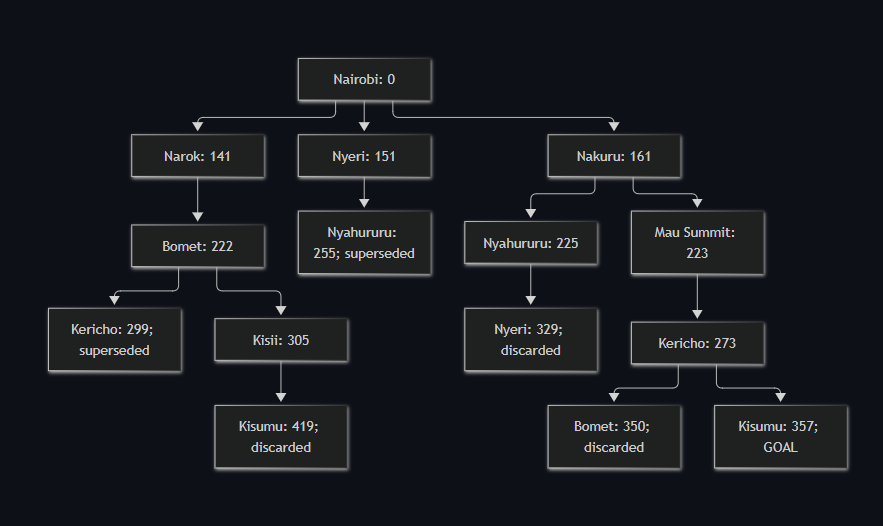

Cumulative Graph that we will be using

In [ ]:
# Step 1: Create a graph, extract the nodes and add attach the costs
# We'll use an adjacency list (id, city, cost, parent and children)
# using ids because certain cities have more than 1 way to get to the place

nodes = {
    "N1": {
        "city": "Nairobi",
        "cost": 0,
        "parent": None,
        "children": ["N2", "N3", "N4"]
    },

    "N2": {
        "city": "Narok",
        "cost": 141,
        "parent": "N1",
        "children": ["N5"]
    },

    "N3": {
        "city": "Nyeri",
        "cost": 151,
        "parent": "N1",
        "children": ["N7"]
    },

    "N4": {
        "city": "Nakuru",
        "cost": 161,
        "parent": "N1",
        "children": ["N6", "N8"]
    },

    "N5": {
        "city": "Bomet",
        "cost": 222,
        "parent": "N2",
        "children": ["N9", "N11"]
    },

    "N6": {
        "city": "Nyahururu",
        "cost": 225,
        "parent": "N4",
        "children": ["N10"]
    },

    "N7": {
        "city": "Nyahururu",
        "cost": 255,
        "parent": "N3",
        "children": []
    },

    "N8": {
        "city": "Mau Summit",
        "cost": 223,
        "parent": "N4",
        "children": ["N12"]
    },

    "N9": {
        "city": "Kericho",
        "cost": 299,
        "parent": "N5",
        "children": []
    },

    "N10": {
        "city": "Nyeri",
        "cost": 329,
        "parent": "N6",
        "children": []
    },

    "N11": {
        "city": "Kisii",
        "cost": 305,
        "parent": "N5",
        "children": ["N13"]
    },

    "N12": {
        "city": "Kericho",
        "cost": 273,
        "parent": "N8",
        "children": ["N14", "N15"]
    },

    "N13": {
        "city": "Kisumu",
        "cost": 419,
        "parent": "N11",
        "children": []
    },

    "N14": {
        "city": "Bomet",
        "cost": 350,
        "parent": "N12",
        "children": []
    },

    "N15": {
        "city": "Kisumu",
        "cost": 357,
        "parent": "N12",
        "children": []
    }
}

In [ ]:
# This implementation uses a heapq to help with priority exploration
# count helps decide on ties so that ids are not used
import heapq
from itertools import count

In [ ]:
def uniform_cost_search(nodes, start, goal):

    # Initializing
    frontier = []
    exploration_order = []

    sequence = count()

    # Adding the start node
    # next(sequence is the count we imported earlier)
    heapq.heappush(
        frontier,
        (nodes[start]["cost"], next(sequence), start)
    )

    # conditional that checks the heap
    while frontier:

        # node with lowest cost is removed
        current_cost, _, current_id = heapq.heappop(frontier)

        current_city = nodes[current_id]["city"]

        # Record the node being explored
        exploration_order.append(current_id)


        # Check whether the current node is the goal
        # program doesesn't terminate here though
        if current_city == goal:
            print(f"Goal reached: {current_city}")

        # Expand the current node because they have children
        for child_id in nodes[current_id]["children"]:

            child_cost = nodes[child_id]["cost"]

            # each child is added to the frontier
            heapq.heappush(
                frontier,
                (child_cost, next(sequence), child_id)
            )
# the exploration is complete when the frontier is empty hence the loop is exited
    print("\nExploration complete.")

    return exploration_order

In [ ]:
# execution
exploration_order = uniform_cost_search(
    nodes,
    start="N1",
    goal="Kisumu"
)

Goal reached: Kisumu
Goal reached: Kisumu

Exploration complete.


In [ ]:
# shows all routes traversed

for node_id in exploration_order:
    print(
        nodes[node_id]["city"],
        nodes[node_id]["cost"]
    )


Nairobi 0
Narok 141
Nyeri 151
Nakuru 161
Bomet 222
Mau Summit 223
Nyahururu 225
Nyahururu 255
Kericho 273
Kericho 299
Kisii 305
Nyeri 329
Bomet 350
Kisumu 357
Kisumu 419
